# NN_L5_vol_mse

**Test MSE of the log Garman-Klass variance of the S&P 500, 2020-2026: naive, GARCH(1,1), HAR and RNN, LSTM, GRU (5 seeds each), with Diebold-Mariano tests.**

Neural Networks and Deep Learning (NN), Lecture 5 · Daniel Traian Pele, Bucharest University of Economic Studies

[Open in Colab](https://colab.research.google.com/github/danpele/NEURAL_BIZ/blob/main/Quantlets/L5/NN_L5_vol_mse/NN_L5_vol_mse.ipynb)

In [1]:
import os
# course data: the local copy of the repository if there is one, else the public repository on GitHub
_LOCAL = os.path.join('..', '..', '..', 'data', 'clean')
DATA = _LOCAL + os.sep if os.path.isdir(_LOCAL) else 'https://raw.githubusercontent.com/danpele/NEURAL_BIZ/main/data/clean/'
REPO = os.path.join('..', '..', '..') + os.sep if os.path.isdir(_LOCAL) else 'https://raw.githubusercontent.com/danpele/NEURAL_BIZ/main/'

In [2]:
import warnings
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
warnings.filterwarnings('ignore')
# course chart style: transparent background, no gridlines, legend at the bottom outside the axes, four-digit years
plt.rcParams.update({
    'figure.facecolor': 'none', 'axes.facecolor': 'none', 'savefig.transparent': True,
    'axes.grid': False, 'axes.spines.top': False, 'axes.spines.right': False,
    'axes.edgecolor': '#222222', 'axes.labelcolor': '#222222', 'xtick.color': '#222222', 'ytick.color': '#222222',
    'text.color': '#222222', 'font.size': 11, 'axes.labelsize': 11, 'legend.fontsize': 10.5, 'legend.frameon': False,
    'lines.linewidth': 1.4, 'font.family': 'DejaVu Sans'})
SERIES = ['#2a78d6', '#eb6834', '#1baf7a', '#eda100', '#e87ba4', '#008300', '#6250d6', '#e34948']
PAL = {'data': '#2a78d6', 'model': '#eb6834', 'benchmark': '#1baf7a', 'alt': '#eda100',
       'train': '#2a78d6', 'valid': '#eb6834', 'test': '#6250d6', 'positive': '#e34948', 'negative': '#2a78d6'}


def legend_bottom(fig, ncol=4):
    h, l_ = [], []
    for ax in fig.axes:
        for hh, ll in zip(*ax.get_legend_handles_labels()):
            if ll not in l_:
                h.append(hh); l_.append(ll)
    if h:
        fig.legend(h, l_, loc='lower center', ncol=min(ncol, len(h)), bbox_to_anchor=(0.5, 0.0), frameon=False)


def show(key, label, value):
    # print a number of the slide; [key] = its name in lectures/Lk/Lk_numbers.json
    print(f'{label} = {value}   [{key}]')

Benchmarks first; networks with 5 seeds; Diebold-Mariano test with Newey-West variance.

naive MSE = 0.9657   [vol.naive.mse]
garch MSE = 0.7861   [vol.garch.mse]
har MSE = 0.7063   [vol.har.mse]
rnn MSE, mean over seeds = 0.6491   [vol.rnn.mse_mean]
lstm MSE, mean over seeds = 0.6277   [vol.lstm.mse_mean]
gru MSE, mean over seeds = 0.629   [vol.gru.mse_mean]
DM LSTM vs HAR = -5.52   [vol.dm_lstm_har.stat]
p-value = 0.0   [vol.dm_lstm_har.p]


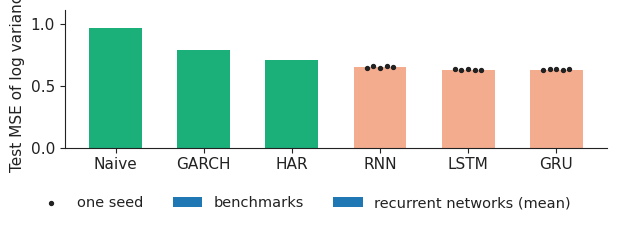

In [3]:
import json, urllib.request
_F = 'vol_mse_results.json'
R = json.load(open(_F)) if os.path.isfile(_F) else json.load(urllib.request.urlopen(REPO + 'Quantlets/L5/NN_L5_vol_mse/' + _F))
from scipy.stats import norm
y = np.array(R['y']); mse = lambda p: float(np.mean((np.asarray(p) - y) ** 2))
def dm(e1, e2):
    dd = e1 - e2; n = len(dd); dc = dd - dd.mean(); L = int(np.floor(4 * (n / 100) ** (2 / 9))); v = dc @ dc / n
    for k in range(1, L + 1): v += 2 * (1 - k / (L + 1)) * (dc[k:] @ dc[:-k]) / n
    s = dd.mean() / np.sqrt(v / n); return s, 2 * (1 - norm.cdf(abs(s)))
for k in ['naive', 'garch', 'har']: show(f'vol.{k}.mse', f'{k} MSE', round(mse(R[k]), 4))
for c in ['rnn', 'lstm', 'gru']: show(f'vol.{c}.mse_mean', f'{c} MSE, mean over seeds', round(float(np.mean([mse(p) for p in R[c]])), 4))
ens = np.array(R['lstm']).mean(0); s, p = dm((ens - y) ** 2, (np.array(R['har']) - y) ** 2)
show('vol.dm_lstm_har.stat', 'DM LSTM vs HAR', round(float(s), 2)); show('vol.dm_lstm_har.p', 'p-value', round(float(p), 3))
fig, ax = plt.subplots(figsize=(6.4, 2.3)); names = ['Naive', 'GARCH', 'HAR', 'RNN', 'LSTM', 'GRU']
vals = [mse(R[k]) for k in ['naive', 'garch', 'har']]
for i, v_ in enumerate(vals): ax.bar(i, v_, color=PAL['benchmark'], width=.6)
for i, c in enumerate(['rnn', 'lstm', 'gru']):
    ms = [mse(p) for p in R[c]]; ax.bar(3 + i, np.mean(ms), color=PAL['model'], width=.6, alpha=.55)
    ax.scatter(np.full(len(ms), 3 + i) + np.linspace(-.15, .15, len(ms)), ms, color='#222222', s=8, zorder=3)
ax.set_xticks(range(6)); ax.set_xticklabels(names); ax.set_ylabel('Test MSE of log variance'); ax.set_ylim(0, max(vals) * 1.15)
ax.bar([], [], color=PAL['benchmark'], label='benchmarks'); ax.bar([], [], color=PAL['model'], alpha=.55, label='recurrent networks (mean)'); ax.scatter([], [], color='#222222', s=8, label='one seed')
legend_bottom(fig, ncol=3); fig.tight_layout(rect=(0, .15, 1, 1))
fig.savefig('vol_mse.png', dpi=200, transparent=True, bbox_inches='tight')
plt.show()